In [1]:
import sys

print(sys.executable)
print(sys.version)


c:\Users\pkara\Documents\disaster-damage-detection\.venv\Scripts\python.exe
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [2]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("Notebook ortamı hazır.")

Notebook ortamı hazır.


In [3]:
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data"
train_dir = data_dir / "train"

images_dir = train_dir / "images"
labels_dir = train_dir / "labels"
targets_dir = train_dir / "targets"

print("Proje:", project_root)
print("Images bulundu mu?:", images_dir.exists())
print("Labels bulundu mu?:", labels_dir.exists())
print("Targets bulundu mu?:", targets_dir.exists())

Proje: c:\Users\pkara\Documents\disaster-damage-detection
Images bulundu mu?: True
Labels bulundu mu?: True
Targets bulundu mu?: True


In [4]:
pre_images = list(images_dir.glob("*_pre_disaster.png"))
post_images = list(images_dir.glob("*_post_disaster.png"))

print("Pre-disaster görüntü sayısı:", len(pre_images))
print("Post-disaster görüntü sayısı:", len(post_images))
pre_ids = {
    path.name.replace("_pre_disaster.png", "")
    for path in pre_images
}

post_ids = {
    path.name.replace("_post_disaster.png", "")
    for path in post_images
}

matched_ids = pre_ids.intersection(post_ids)

print("Eşleşmiş pre/post çifti:", len(matched_ids))
print("Pre olup post olmayan:", len(pre_ids - post_ids))
print("Post olup pre olmayan:", len(post_ids - pre_ids))
post_labels = list(labels_dir.glob("*_post_disaster.json"))

print("Post-disaster JSON sayısı:", len(post_labels))

Pre-disaster görüntü sayısı: 2799
Post-disaster görüntü sayısı: 2799
Eşleşmiş pre/post çifti: 2799
Pre olup post olmayan: 0
Post olup pre olmayan: 0
Post-disaster JSON sayısı: 2799


In [5]:
from collections import Counter

disaster_counts = Counter()

for sample_id in matched_ids:
    disaster_name = sample_id.rsplit("_", 1)[0]
    disaster_counts[disaster_name] += 1

print("Toplam farklı afet sayısı:", len(disaster_counts))
print()

for disaster, count in sorted(disaster_counts.items()):
    print(f"{disaster}: {count} görüntü çifti")

Toplam farklı afet sayısı: 10

guatemala-volcano: 18 görüntü çifti
hurricane-florence: 319 görüntü çifti
hurricane-harvey: 319 görüntü çifti
hurricane-matthew: 238 görüntü çifti
hurricane-michael: 343 görüntü çifti
mexico-earthquake: 121 görüntü çifti
midwest-flooding: 279 görüntü çifti
palu-tsunami: 113 görüntü çifti
santa-rosa-wildfire: 226 görüntü çifti
socal-fire: 823 görüntü çifti


In [6]:
disaster_df = pd.DataFrame(
    sorted(disaster_counts.items()),
    columns=["afet", "goruntu_cifti"]
)

disaster_df

,afet,goruntu_cifti
0,guatemala-volcano,18
1,hurricane-florence,319
2,hurricane-harvey,319
3,hurricane-matthew,238
4,hurricane-michael,343
5,mexico-earthquake,121
6,midwest-flooding,279
7,palu-tsunami,113
8,santa-rosa-wildfire,226
9,socal-fire,823


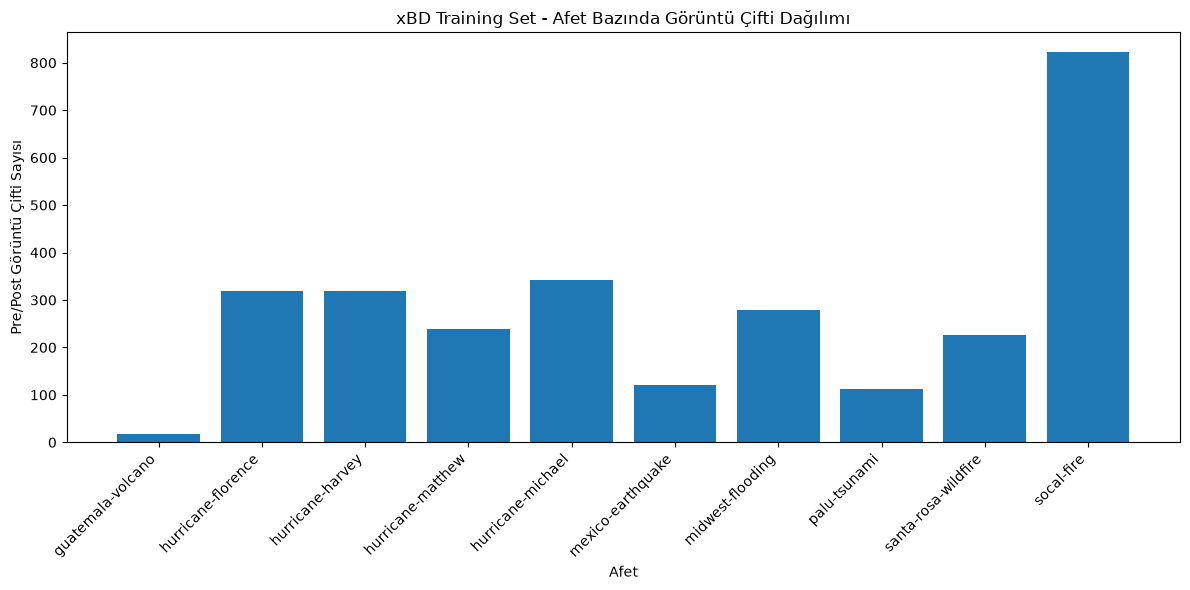

In [7]:
plt.figure(figsize=(12, 6))

plt.bar(
    disaster_df["afet"],
    disaster_df["goruntu_cifti"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Afet")
plt.ylabel("Pre/Post Görüntü Çifti Sayısı")
plt.title("xBD Training Set - Afet Bazında Görüntü Çifti Dağılımı")

plt.tight_layout()
plt.show()

In [8]:
post_labels = list(labels_dir.glob("*_post_disaster.json"))

print("Post-disaster JSON sayısı:", len(post_labels))
print("İlk örnek:", post_labels[0].name)

Post-disaster JSON sayısı: 2799
İlk örnek: guatemala-volcano_00000000_post_disaster.json


In [9]:
sample_json_path = post_labels[0]

with open(sample_json_path, "r", encoding="utf-8") as f:
    sample_json = json.load(f)

print(sample_json.keys())

dict_keys(['features', 'metadata'])


In [10]:
sample_json

{'features': {'lng_lat': [{'properties': {'feature_type': 'building',
     'subtype': 'no-damage',
     'uid': '486b0813-ecd2-4b84-856c-9c0e42156953'},
    'wkt': 'POLYGON ((-90.81544679490855 14.39086318334812, -90.81537467350067 14.39060467857134, -90.81584174451893 14.39043032647906, -90.81586635209965 14.39049581582557, -90.81593344431286 14.39048145754227, -90.81595559689623 14.39057367091926, -90.81587964155047 14.39059650626524, -90.81590706308843 14.39071123556855, -90.81544679490855 14.39086318334812))'},
   {'properties': {'feature_type': 'building',
     'subtype': 'no-damage',
     'uid': '139cf2c8-ad52-4739-82b5-bb646b215e76'},
    'wkt': 'POLYGON ((-90.81420592027385 14.38829423654861, -90.81421178336095 14.38832937106001, -90.81408837763853 14.38834314934208, -90.81404547543569 14.38816089961379, -90.81410016818667 14.38815172795384, -90.8141122317199 14.38818732301324, -90.81427959937533 14.38816185446788, -90.81428289441583 14.38820583612065, -90.81412306222495 14.3882

In [11]:
print(sample_json["features"].keys())

dict_keys(['lng_lat', 'xy'])


In [12]:
buildings = sample_json["features"]["xy"]

print("Bu görüntüdeki bina sayısı:", len(buildings))
print("İlk binanın özellikleri:")
print(buildings[0]["properties"])

print("\nİlk binanın poligonu:")
print(buildings[0]["wkt"])

Bu görüntüdeki bina sayısı: 10
İlk binanın özellikleri:
{'feature_type': 'building', 'subtype': 'no-damage', 'uid': '486b0813-ecd2-4b84-856c-9c0e42156953'}

İlk binanın poligonu:
POLYGON ((532.1863714054954 165.9824503000504, 548.6019827848852 224.1613082732768, 446.2458177229872 264.4761185678668, 440.6934785817455 249.7503495372735, 425.9677095499687 253.1300342329752, 420.8981825090282 232.3691139606, 437.5551999358392 227.0581808684396, 431.2786426428399 201.2277335525121, 532.1863714054954 165.9824503000504))


In [13]:
from collections import Counter

damage_counts = Counter()

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    buildings = data["features"]["xy"]

    for building in buildings:
        subtype = building["properties"].get("subtype")

        if subtype:
            damage_counts[subtype] += 1

print("Hasar sınıfı dağılımı:")
for damage_type, count in damage_counts.items():
    print(f"{damage_type}: {count}")

Hasar sınıfı dağılımı:
no-damage: 117426
minor-damage: 14980
destroyed: 13227
major-damage: 14161
un-classified: 2993


In [14]:
damage_df = pd.DataFrame(
    damage_counts.items(),
    columns=["hasar_sinifi", "bina_sayisi"]
)

damage_df = damage_df.sort_values(
    "bina_sayisi",
    ascending=False
).reset_index(drop=True)

damage_df

,hasar_sinifi,bina_sayisi
0,no-damage,117426
1,minor-damage,14980
2,major-damage,14161
3,destroyed,13227
4,un-classified,2993


In [15]:
classified_df = damage_df[
    damage_df["hasar_sinifi"] != "un-classified"
].copy()

classified_df["oran_yuzde"] = (
    classified_df["bina_sayisi"]
    / classified_df["bina_sayisi"].sum()
    * 100
)

classified_df

,hasar_sinifi,bina_sayisi,oran_yuzde
0,no-damage,117426,73.485863
1,minor-damage,14980,9.374570
2,major-damage,14161,8.862035
3,destroyed,13227,8.277532


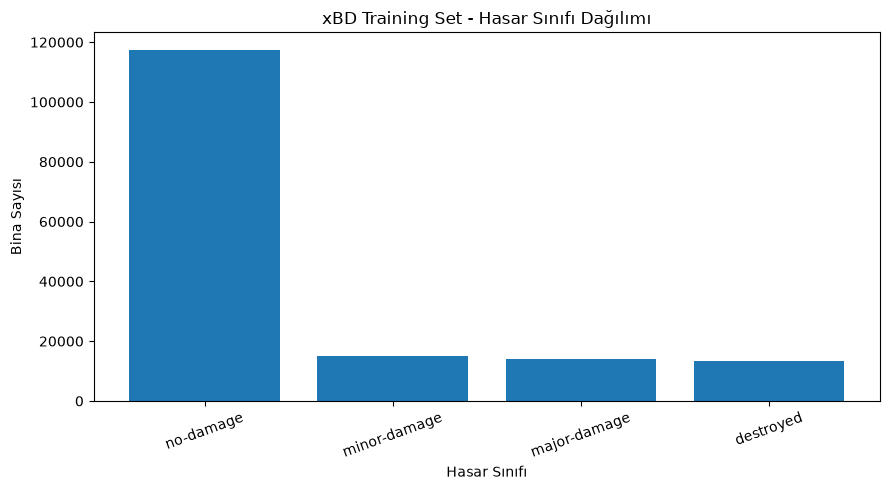

In [16]:
plt.figure(figsize=(9, 5))

plt.bar(
    classified_df["hasar_sinifi"],
    classified_df["bina_sayisi"]
)

plt.xlabel("Hasar Sınıfı")
plt.ylabel("Bina Sayısı")
plt.title("xBD Training Set - Hasar Sınıfı Dağılımı")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [17]:
records = []

for json_path in post_labels:
    # Örnek:
    # mexico-earthquake_00000123_post_disaster.json
    sample_id = json_path.name.replace("_post_disaster.json", "")
    disaster_name = sample_id.rsplit("_", 1)[0]

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    buildings = data["features"]["xy"]

    for building in buildings:
        properties = building["properties"]
        subtype = properties.get("subtype")

        if subtype:
            records.append({
                "afet": disaster_name,
                "ornek_id": sample_id,
                "hasar_sinifi": subtype,
                "bina_uid": properties.get("uid")
            })

buildings_df = pd.DataFrame(records)

print("Toplam bina kaydı:", len(buildings_df))
buildings_df.head()

Toplam bina kaydı: 162787


,afet,ornek_id,hasar_sinifi,bina_uid
0,guatemala-volcano,guatemala-volcano_00000000,no-damage,486b0813-ecd2-4b84-856c-9c0e42156953
1,guatemala-volcano,guatemala-volcano_00000000,no-damage,139cf2c8-ad52-4739-82b5-bb646b215e76
2,guatemala-volcano,guatemala-volcano_00000000,no-damage,d43deb4a-529c-4df4-b666-26dd5b17e040
3,guatemala-volcano,guatemala-volcano_00000000,no-damage,563b145d-732d-4eb4-8c77-380519842324
4,guatemala-volcano,guatemala-volcano_00000000,no-damage,56f51b26-d511-461d-bb31-747901a4ea75


In [18]:
afet_hasar_tablosu = pd.crosstab(
    buildings_df["afet"],
    buildings_df["hasar_sinifi"]
)

afet_hasar_tablosu

hasar_sinifi,destroyed,major-damage,minor-damage,no-damage,un-classified
afet,,,,,
guatemala-volcano,25,9,9,639,174
hurricane-florence,54,1245,132,4689,326
hurricane-harvey,401,8238,2663,11423,289
hurricane-matthew,2147,1945,6548,2515,784
hurricane-michael,757,1902,5207,14588,232
mexico-earthquake,2,18,110,32066,75
midwest-flooding,75,119,149,8128,285
palu-tsunami,4966,571,1,25455,401
santa-rosa-wildfire,3471,63,78,9285,53


In [19]:
deprem_afetleri = [
    "mexico-earthquake",
    "palu-tsunami"
]

deprem_df = buildings_df[
    buildings_df["afet"].isin(deprem_afetleri)
].copy()

deprem_hasar_tablosu = pd.crosstab(
    deprem_df["afet"],
    deprem_df["hasar_sinifi"]
)

deprem_hasar_tablosu

hasar_sinifi,destroyed,major-damage,minor-damage,no-damage,un-classified
afet,,,,,
mexico-earthquake,2,18,110,32066,75
palu-tsunami,4966,571,1,25455,401


In [20]:
deprem_classified = deprem_df[
    deprem_df["hasar_sinifi"] != "un-classified"
].copy()

deprem_dagilim = (
    deprem_classified["hasar_sinifi"]
    .value_counts()
    .to_frame("bina_sayisi")
)

deprem_dagilim["oran_yuzde"] = (
    deprem_dagilim["bina_sayisi"]
    / deprem_dagilim["bina_sayisi"].sum()
    * 100
)

deprem_dagilim

,bina_sayisi,oran_yuzde
hasar_sinifi,,
no-damage,57521,91.030084
destroyed,4968,7.862128
major-damage,589,0.932124
minor-damage,111,0.175663


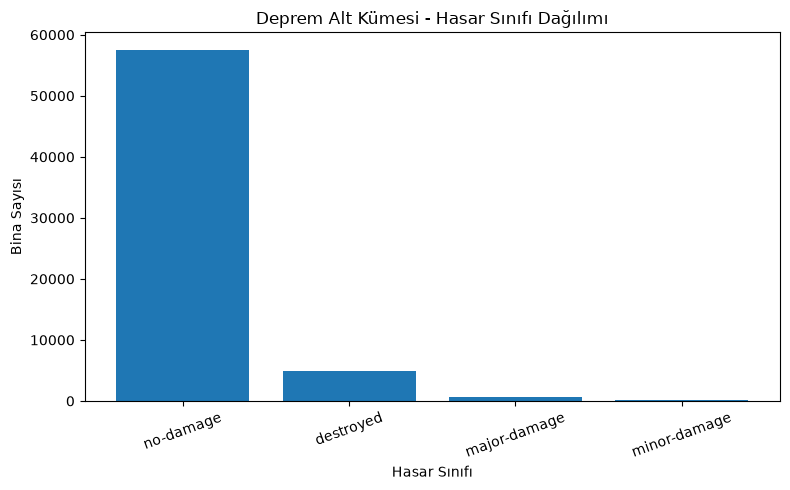

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    deprem_dagilim.index,
    deprem_dagilim["bina_sayisi"]
)

plt.xlabel("Hasar Sınıfı")
plt.ylabel("Bina Sayısı")
plt.title("Deprem Alt Kümesi - Hasar Sınıfı Dağılımı")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

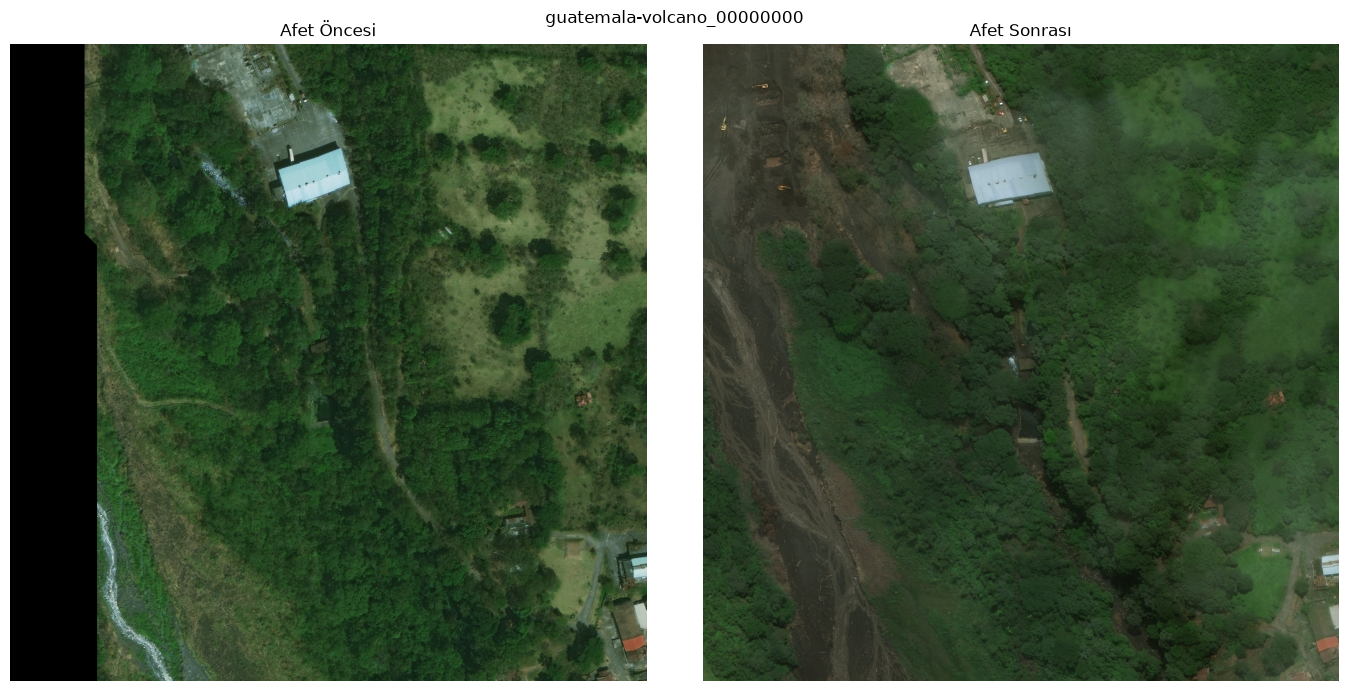

In [22]:
example_id = sorted(matched_ids)[0]

pre_path = images_dir / f"{example_id}_pre_disaster.png"
post_path = images_dir / f"{example_id}_post_disaster.png"

pre_img = Image.open(pre_path)
post_img = Image.open(post_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(pre_img)
axes[0].set_title("Afet Öncesi")
axes[0].axis("off")

axes[1].imshow(post_img)
axes[1].set_title("Afet Sonrası")
axes[1].axis("off")

plt.suptitle(example_id)
plt.tight_layout()
plt.show()

In [23]:
hasar_siniflari = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

ornekler = {}

for hasar in hasar_siniflari:
    satirlar = buildings_df[
        buildings_df["hasar_sinifi"] == hasar
    ]

    if not satirlar.empty:
        ornekler[hasar] = satirlar.iloc[0]["ornek_id"]

ornekler

{'no-damage': 'guatemala-volcano_00000000',
 'minor-damage': 'guatemala-volcano_00000001',
 'major-damage': 'guatemala-volcano_00000019',
 'destroyed': 'guatemala-volcano_00000002'}

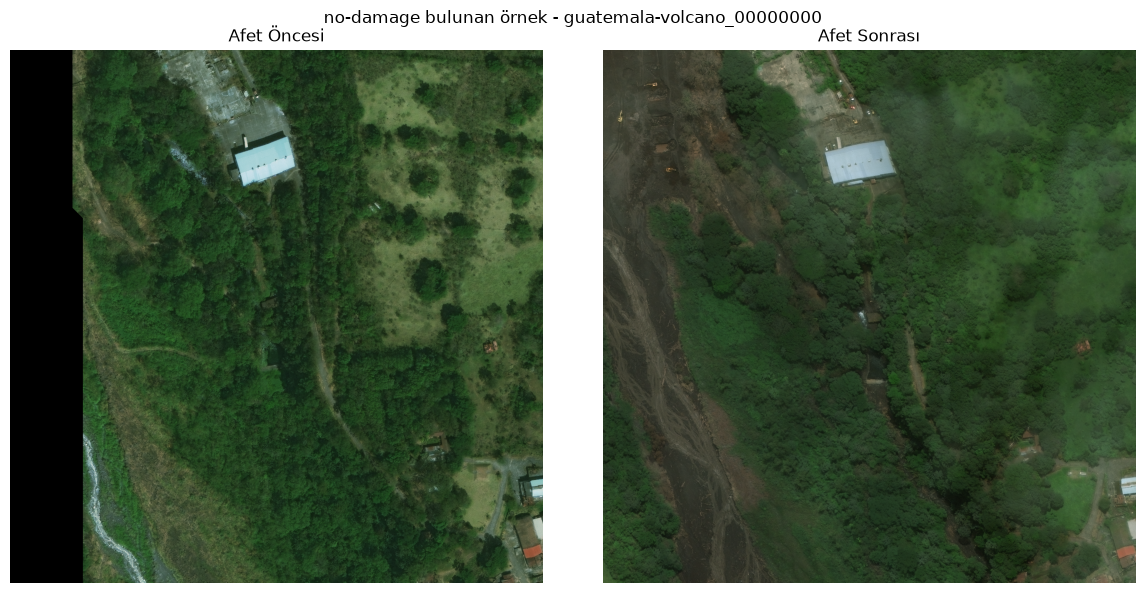

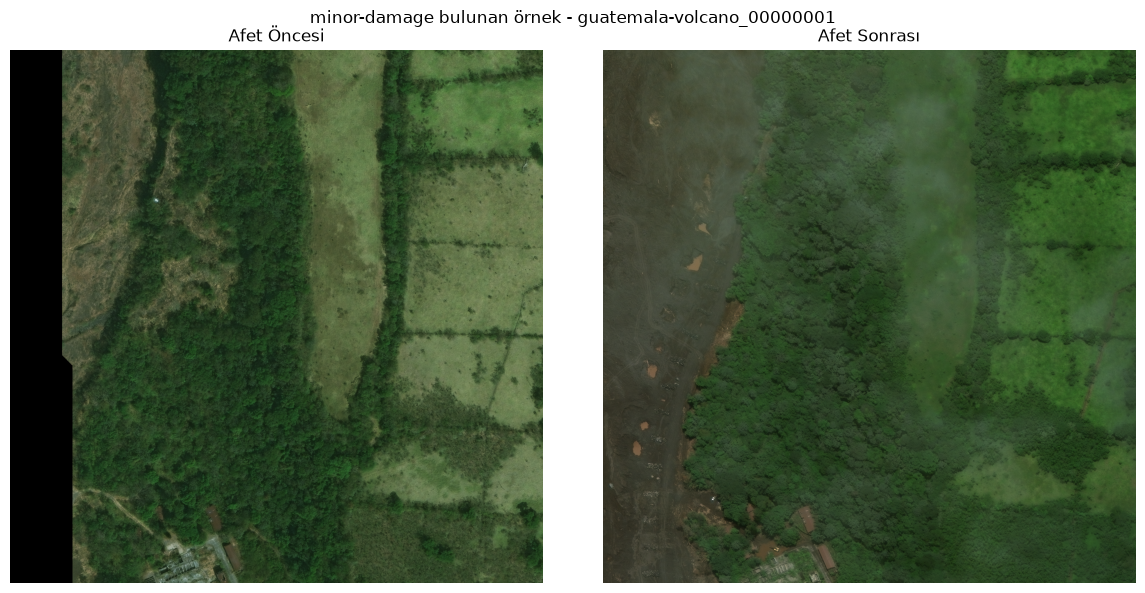

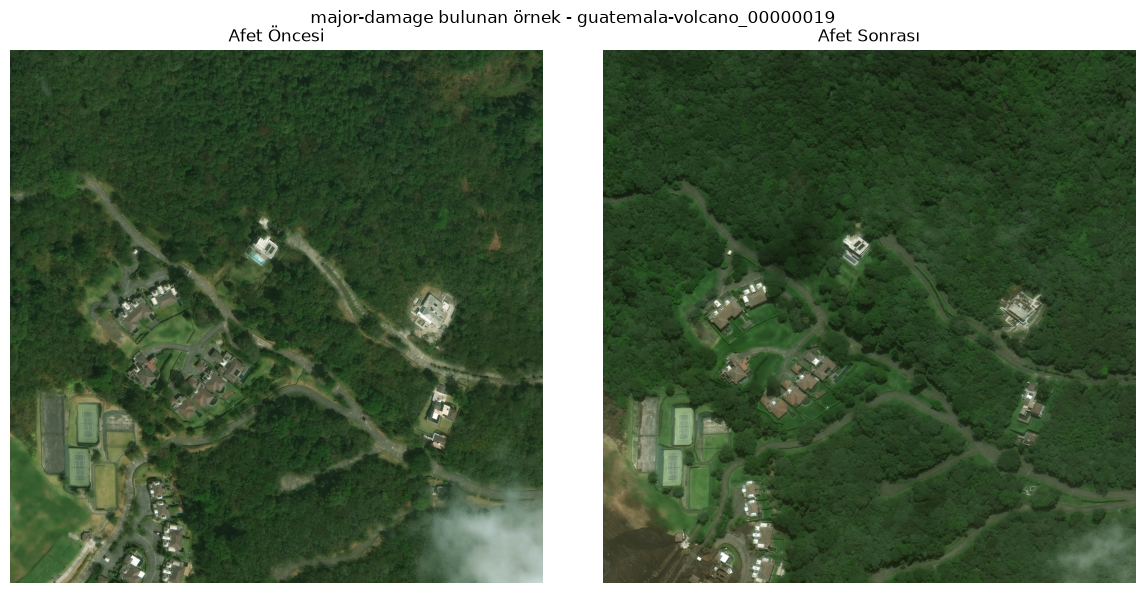

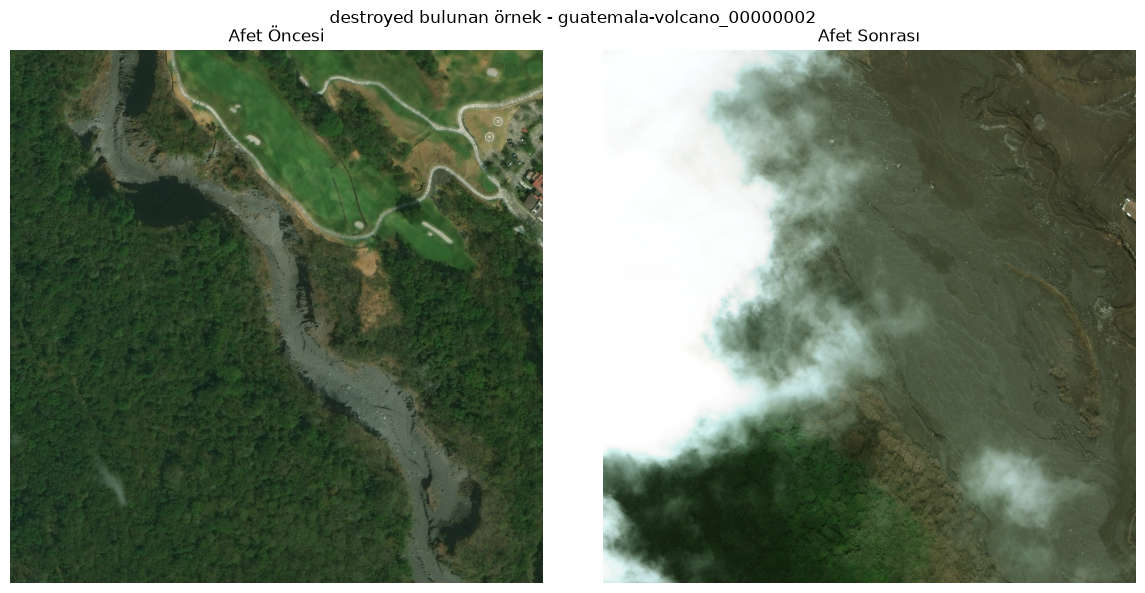

In [24]:
for hasar, example_id in ornekler.items():

    pre_path = images_dir / f"{example_id}_pre_disaster.png"
    post_path = images_dir / f"{example_id}_post_disaster.png"

    pre_img = Image.open(pre_path)
    post_img = Image.open(post_path)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(pre_img)
    axes[0].set_title("Afet Öncesi")
    axes[0].axis("off")

    axes[1].imshow(post_img)
    axes[1].set_title("Afet Sonrası")
    axes[1].axis("off")

    plt.suptitle(f"{hasar} bulunan örnek - {example_id}")
    plt.tight_layout()
    plt.show()

In [25]:
from shapely import wkt

print("Shapely hazır.")

Shapely hazır.


In [26]:
building_sizes = []

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    buildings = data["features"]["xy"]

    for building in buildings:
        subtype = building["properties"].get("subtype")

        # Eğitimde kullanmayacağımız belirsiz etiketleri atla
        if subtype == "un-classified":
            continue

        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        polygon = wkt.loads(polygon_text)

        min_x, min_y, max_x, max_y = polygon.bounds

        width = max_x - min_x
        height = max_y - min_y

        building_sizes.append({
            "genislik": width,
            "yukseklik": height,
            "hasar_sinifi": subtype
        })

sizes_df = pd.DataFrame(building_sizes)

print("Ölçülen bina sayısı:", len(sizes_df))
sizes_df.head()

Ölçülen bina sayısı: 159794


,genislik,yukseklik,hasar_sinifi
0,127.703800,98.493668,no-damage
1,52.315456,43.217116,no-damage
2,46.559580,36.146230,no-damage
3,20.393352,41.941272,no-damage
4,58.998294,105.093275,no-damage


In [27]:
sizes_df[["genislik", "yukseklik"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,genislik,yukseklik
count,159794.000000,159794.000000
mean,35.555799,34.941728
std,24.235298,23.174405
min,0.920000,0.996833
25%,20.130783,19.689402
50%,31.422029,30.872506
75%,45.000000,44.777437
90%,59.000000,58.436995
95%,71.725663,70.341253
99%,119.214015,115.295925


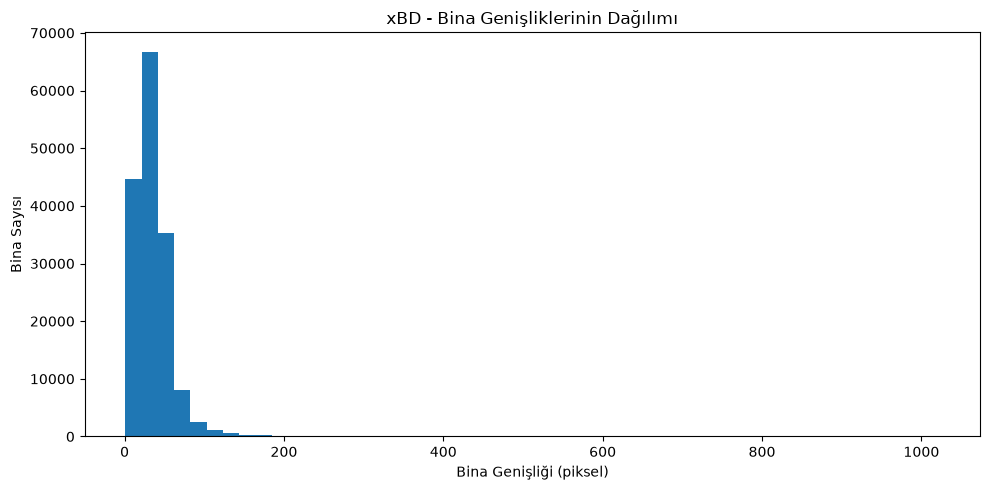

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    sizes_df["genislik"],
    bins=50
)

plt.xlabel("Bina Genişliği (piksel)")
plt.ylabel("Bina Sayısı")
plt.title("xBD - Bina Genişliklerinin Dağılımı")

plt.tight_layout()
plt.show()

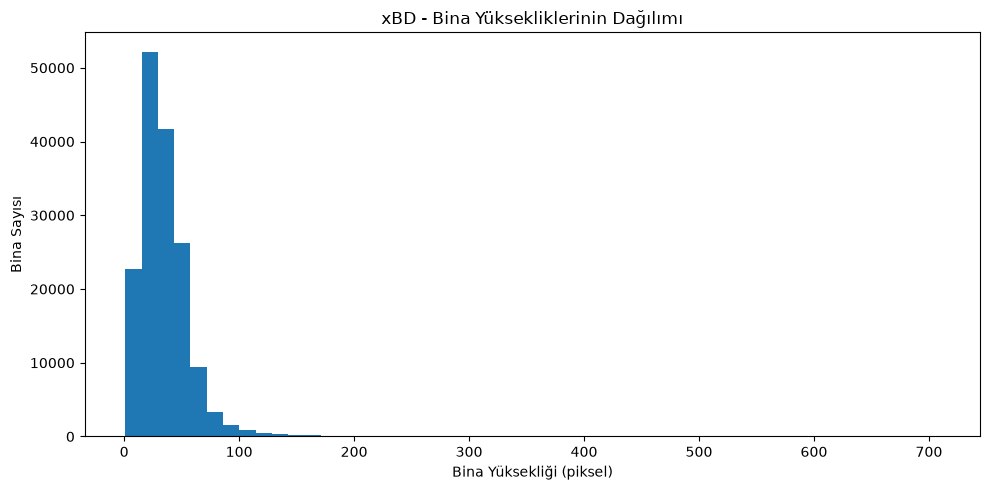

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(
    sizes_df["yukseklik"],
    bins=50
)

plt.xlabel("Bina Yüksekliği (piksel)")
plt.ylabel("Bina Sayısı")
plt.title("xBD - Bina Yüksekliklerinin Dağılımı")

plt.tight_layout()
plt.show()

In [30]:
sizes_df[["genislik", "yukseklik"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,genislik,yukseklik
count,159794.000000,159794.000000
mean,35.555799,34.941728
std,24.235298,23.174405
min,0.920000,0.996833
25%,20.130783,19.689402
50%,31.422029,30.872506
75%,45.000000,44.777437
90%,59.000000,58.436995
95%,71.725663,70.341253
99%,119.214015,115.295925


# Faz 2 Sonuçları

## Veri Seti
- Challenge Training Set kullanıldı.
- 2799 afet öncesi görüntü bulundu.
- 2799 afet sonrası görüntü bulundu.
- 2799 pre/post görüntü çifti eksiksiz eşleşti.
- Training set içinde 10 farklı afet olayı bulundu.

## Hasar Sınıfları
Toplam bina etiketleri:
- no-damage: 117426
- minor-damage: 14980
- major-damage: 14161
- destroyed: 13227
- un-classified: 2993

`un-classified` örnekleri model eğitiminden çıkarılacaktır.

Veri setinde belirgin bir sınıf dengesizliği vardır.
Özellikle no-damage sınıfı diğer sınıflardan çok daha fazladır.

## Deprem Alt Kümesi
Mexico Earthquake ve Palu Tsunami ayrı incelendi.

Deprem alt kümesinde sınıf dağılımının ciddi biçimde dengesiz olduğu görüldü.
Bu nedenle nihai modelin yalnızca deprem verisiyle eğitilmesi yerine,
tüm uygun xBD afetlerinin eğitimde kullanılması ve deprem performansının
ayrıca raporlanması planlanmaktadır.

## Görsel Kontrol
Afet öncesi ve sonrası uydu görüntü çiftleri başarıyla görselleştirildi.

Her hasar sınıfını içeren örnek görüntüler incelendi.

## Bina Boyutları
Yaklaşık sonuçlar:
- Medyan bina genişliği: 31 px
- Medyan bina yüksekliği: 31 px
- %90 genişlik: yaklaşık 59 px
- %95 genişlik: yaklaşık 72 px
- %99 genişlik: yaklaşık 119 px

Bu nedenle Faz 3 için başlangıç bina patch boyutu olarak
128x128 piksel kullanılması planlanmaktadır.

Bu karar Faz 3 sırasında gerekli bağlam payı ve resize işlemleri
test edilerek yeniden değerlendirilebilir.

afet_bina_sayilari = (
    buildings_df
    .groupby("afet")
    .size()
    .reset_index(name="bina_sayisi")
)

afet_ozet = disaster_df.merge(
    afet_bina_sayilari,
    on="afet",
    how="left"
)

afet_ozet

In [31]:
afet_bina_sayilari = (
    buildings_df
    .groupby("afet")
    .size()
    .reset_index(name="bina_sayisi")
)

afet_ozet = disaster_df.merge(
    afet_bina_sayilari,
    on="afet",
    how="left"
)

afet_ozet

,afet,goruntu_cifti,bina_sayisi
0,guatemala-volcano,18,856
1,hurricane-florence,319,6446
2,hurricane-harvey,319,23014
3,hurricane-matthew,238,13939
4,hurricane-michael,343,22686
5,mexico-earthquake,121,32271
6,midwest-flooding,279,8756
7,palu-tsunami,113,31394
8,santa-rosa-wildfire,226,12950
9,socal-fire,823,10475


In [32]:
afet_turleri = {}

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    sample_id = json_path.name.replace("_post_disaster.json", "")
    afet = sample_id.rsplit("_", 1)[0]

    metadata = data.get("metadata", {})
    afet_turu = metadata.get("disaster_type", "unknown")

    afet_turleri[afet] = afet_turu

afet_turleri

{'guatemala-volcano': 'volcano',
 'hurricane-florence': 'flooding',
 'hurricane-harvey': 'flooding',
 'hurricane-matthew': 'wind',
 'hurricane-michael': 'wind',
 'mexico-earthquake': 'earthquake',
 'midwest-flooding': 'flooding',
 'palu-tsunami': 'tsunami',
 'santa-rosa-wildfire': 'fire',
 'socal-fire': 'fire'}

In [33]:
print("Afet olayı sayısı:", len(afet_turleri))
print("Afet türü sayısı:", len(set(afet_turleri.values())))

pd.DataFrame(
    afet_turleri.items(),
    columns=["afet", "afet_turu"]
)

Afet olayı sayısı: 10
Afet türü sayısı: 6


,afet,afet_turu
0,guatemala-volcano,volcano
1,hurricane-florence,flooding
2,hurricane-harvey,flooding
3,hurricane-matthew,wind
4,hurricane-michael,wind
5,mexico-earthquake,earthquake
6,midwest-flooding,flooding
7,palu-tsunami,tsunami
8,santa-rosa-wildfire,fire
9,socal-fire,fire


In [34]:
matthew_df = buildings_df[
    buildings_df["afet"] == "hurricane-matthew"
].copy()

matthew_dagilim = (
    matthew_df["hasar_sinifi"]
    .value_counts()
    .to_frame("bina_sayisi")
)

matthew_dagilim

,bina_sayisi
hasar_sinifi,
minor-damage,6548
no-damage,2515
destroyed,2147
major-damage,1945
un-classified,784


In [35]:
print("Hurricane Matthew toplam bina:", len(matthew_df))
print(
    "Hurricane Matthew görüntü çifti:",
    disaster_counts["hurricane-matthew"]
)

Hurricane Matthew toplam bina: 13939
Hurricane Matthew görüntü çifti: 238


In [36]:
from shapely import wkt

building_records = []

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    sample_id = json_path.name.replace("_post_disaster.json", "")
    afet = sample_id.rsplit("_", 1)[0]

    metadata = data.get("metadata", {})
    afet_turu = metadata.get("disaster_type", "unknown")

    for building in data["features"]["xy"]:
        props = building["properties"]
        subtype = props.get("subtype")
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        try:
            polygon = wkt.loads(polygon_text)
            min_x, min_y, max_x, max_y = polygon.bounds

            width = max_x - min_x
            height = max_y - min_y

            short_side = min(width, height)
            long_side = max(width, height)

            aspect_ratio = (
                long_side / short_side
                if short_side > 0
                else float("inf")
            )

            # Dokümandaki bozuk-poligon kriterleri
            covers_whole_image = width >= 1000 or height >= 1000
            too_thin = short_side < 3
            extreme_aspect = aspect_ratio > 10

            is_bad_polygon = (
                covers_whole_image
                or too_thin
                or extreme_aspect
            )

            building_records.append({
                "afet": afet,
                "afet_turu": afet_turu,
                "ornek_id": sample_id,
                "bina_uid": props.get("uid"),
                "hasar_sinifi": subtype,
                "min_x": min_x,
                "min_y": min_y,
                "max_x": max_x,
                "max_y": max_y,
                "genislik": width,
                "yukseklik": height,
                "uzun_kenar": long_side,
                "aspect_ratio": aspect_ratio,
                "covers_whole_image": covers_whole_image,
                "too_thin": too_thin,
                "extreme_aspect": extreme_aspect,
                "is_bad_polygon": is_bad_polygon
            })

        except Exception as e:
            print("Polygon okunamadı:", json_path.name, e)

buildings_full_df = pd.DataFrame(building_records)

print("Toplam bina:", len(buildings_full_df))
print("Bozuk polygon:", buildings_full_df["is_bad_polygon"].sum())

print(
    "Tüm görüntüyü kaplayan:",
    buildings_full_df["covers_whole_image"].sum()
)

print(
    "3 pikselden ince:",
    buildings_full_df["too_thin"].sum()
)

print(
    "En/boy oranı > 10:",
    buildings_full_df["extreme_aspect"].sum()
)

Toplam bina: 162787
Bozuk polygon: 177
Tüm görüntüyü kaplayan: 1
3 pikselden ince: 91
En/boy oranı > 10: 118


In [37]:
processed_dir = data_dir / "processed"
processed_dir.mkdir(exist_ok=True)

csv_path = processed_dir / "buildings.csv"

buildings_full_df.to_csv(
    csv_path,
    index=False
)

print("Kaydedildi:", csv_path)

Kaydedildi: c:\Users\pkara\Documents\disaster-damage-detection\data\processed\buildings.csv


In [38]:
afet_bina_sayilari = (
    buildings_df
    .groupby("afet")
    .size()
    .reset_index(name="bina_sayisi")
)

afet_ozet = disaster_df.merge(
    afet_bina_sayilari,
    on="afet",
    how="left"
)

afet_ozet

,afet,goruntu_cifti,bina_sayisi
0,guatemala-volcano,18,856
1,hurricane-florence,319,6446
2,hurricane-harvey,319,23014
3,hurricane-matthew,238,13939
4,hurricane-michael,343,22686
5,mexico-earthquake,121,32271
6,midwest-flooding,279,8756
7,palu-tsunami,113,31394
8,santa-rosa-wildfire,226,12950
9,socal-fire,823,10475


In [39]:
afet_turleri = {}

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    sample_id = json_path.name.replace("_post_disaster.json", "")
    afet = sample_id.rsplit("_", 1)[0]

    metadata = data.get("metadata", {})
    afet_turu = metadata.get("disaster_type", "unknown")

    afet_turleri[afet] = afet_turu

afet_turleri

{'guatemala-volcano': 'volcano',
 'hurricane-florence': 'flooding',
 'hurricane-harvey': 'flooding',
 'hurricane-matthew': 'wind',
 'hurricane-michael': 'wind',
 'mexico-earthquake': 'earthquake',
 'midwest-flooding': 'flooding',
 'palu-tsunami': 'tsunami',
 'santa-rosa-wildfire': 'fire',
 'socal-fire': 'fire'}

In [40]:
print("Afet olayı sayısı:", len(afet_turleri))
print("Afet türü sayısı:", len(set(afet_turleri.values())))

pd.DataFrame(
    afet_turleri.items(),
    columns=["afet", "afet_turu"]
)

Afet olayı sayısı: 10
Afet türü sayısı: 6


,afet,afet_turu
0,guatemala-volcano,volcano
1,hurricane-florence,flooding
2,hurricane-harvey,flooding
3,hurricane-matthew,wind
4,hurricane-michael,wind
5,mexico-earthquake,earthquake
6,midwest-flooding,flooding
7,palu-tsunami,tsunami
8,santa-rosa-wildfire,fire
9,socal-fire,fire


In [41]:
matthew_df = buildings_df[
    buildings_df["afet"] == "hurricane-matthew"
].copy()

matthew_dagilim = (
    matthew_df["hasar_sinifi"]
    .value_counts()
    .to_frame("bina_sayisi")
)

matthew_dagilim

,bina_sayisi
hasar_sinifi,
minor-damage,6548
no-damage,2515
destroyed,2147
major-damage,1945
un-classified,784


In [42]:
print("Hurricane Matthew toplam bina:", len(matthew_df))
print(
    "Hurricane Matthew görüntü çifti:",
    disaster_counts["hurricane-matthew"]
)

Hurricane Matthew toplam bina: 13939
Hurricane Matthew görüntü çifti: 238


In [43]:
from shapely import wkt

building_records = []

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    sample_id = json_path.name.replace("_post_disaster.json", "")
    afet = sample_id.rsplit("_", 1)[0]

    metadata = data.get("metadata", {})
    afet_turu = metadata.get("disaster_type", "unknown")

    for building in data["features"]["xy"]:
        props = building["properties"]
        subtype = props.get("subtype")
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        try:
            polygon = wkt.loads(polygon_text)
            min_x, min_y, max_x, max_y = polygon.bounds

            width = max_x - min_x
            height = max_y - min_y

            short_side = min(width, height)
            long_side = max(width, height)

            aspect_ratio = (
                long_side / short_side
                if short_side > 0
                else float("inf")
            )

            # Dokümandaki bozuk-poligon kriterleri
            covers_whole_image = width >= 1000 or height >= 1000
            too_thin = short_side < 3
            extreme_aspect = aspect_ratio > 10

            is_bad_polygon = (
                covers_whole_image
                or too_thin
                or extreme_aspect
            )

            building_records.append({
                "afet": afet,
                "afet_turu": afet_turu,
                "ornek_id": sample_id,
                "bina_uid": props.get("uid"),
                "hasar_sinifi": subtype,
                "min_x": min_x,
                "min_y": min_y,
                "max_x": max_x,
                "max_y": max_y,
                "genislik": width,
                "yukseklik": height,
                "uzun_kenar": long_side,
                "aspect_ratio": aspect_ratio,
                "covers_whole_image": covers_whole_image,
                "too_thin": too_thin,
                "extreme_aspect": extreme_aspect,
                "is_bad_polygon": is_bad_polygon
            })

        except Exception as e:
            print("Polygon okunamadı:", json_path.name, e)

buildings_full_df = pd.DataFrame(building_records)

print("Toplam bina:", len(buildings_full_df))
print("Bozuk polygon:", buildings_full_df["is_bad_polygon"].sum())

print(
    "Tüm görüntüyü kaplayan:",
    buildings_full_df["covers_whole_image"].sum()
)

print(
    "3 pikselden ince:",
    buildings_full_df["too_thin"].sum()
)

print(
    "En/boy oranı > 10:",
    buildings_full_df["extreme_aspect"].sum()
)

Toplam bina: 162787
Bozuk polygon: 177
Tüm görüntüyü kaplayan: 1
3 pikselden ince: 91
En/boy oranı > 10: 118


In [44]:
processed_dir = data_dir / "processed"
processed_dir.mkdir(exist_ok=True)

csv_path = processed_dir / "buildings.csv"

buildings_full_df.to_csv(
    csv_path,
    index=False
)

print("Kaydedildi:", csv_path)

Kaydedildi: c:\Users\pkara\Documents\disaster-damage-detection\data\processed\buildings.csv


In [45]:
for threshold in [150, 200, 256, 300, 400, 500, 600, 700, 800, 900, 1000]:
    count = (
        (buildings_full_df["genislik"] >= threshold) |
        (buildings_full_df["yukseklik"] >= threshold)
    ).sum()

    print(f">= {threshold}px : {count}")

>= 150px : 1189
>= 200px : 492
>= 256px : 245
>= 300px : 148
>= 400px : 41
>= 500px : 14
>= 600px : 7
>= 700px : 3
>= 800px : 1
>= 900px : 1
>= 1000px : 1


In [46]:
for threshold in [256, 300, 400, 500, 600, 700, 800]:
    count = (
        (buildings_full_df["genislik"] >= threshold) &
        (buildings_full_df["yukseklik"] >= threshold)
    ).sum()

    print(f"Her iki kenar >= {threshold}px : {count}")

Her iki kenar >= 256px : 38
Her iki kenar >= 300px : 22
Her iki kenar >= 400px : 6
Her iki kenar >= 500px : 2
Her iki kenar >= 600px : 1
Her iki kenar >= 700px : 0
Her iki kenar >= 800px : 0


In [47]:
invalid_count = 0

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for building in data["features"]["xy"]:
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        polygon = wkt.loads(polygon_text)

        if not polygon.is_valid:
            invalid_count += 1

print("Shapely'ye göre geçersiz polygon:", invalid_count)

Shapely'ye göre geçersiz polygon: 1


In [48]:
afet_bina_sayilari = (
    buildings_df
    .groupby("afet")
    .size()
    .reset_index(name="bina_sayisi")
)

afet_ozet = disaster_df.merge(
    afet_bina_sayilari,
    on="afet",
    how="left"
)

afet_ozet

,afet,goruntu_cifti,bina_sayisi
0,guatemala-volcano,18,856
1,hurricane-florence,319,6446
2,hurricane-harvey,319,23014
3,hurricane-matthew,238,13939
4,hurricane-michael,343,22686
5,mexico-earthquake,121,32271
6,midwest-flooding,279,8756
7,palu-tsunami,113,31394
8,santa-rosa-wildfire,226,12950
9,socal-fire,823,10475


In [49]:
# 1) Geometrik olarak geçersiz polygon
invalid_count = 0

# 2) Görüntü sınırlarının dışına çıkan polygon
out_of_bounds_count = 0

# 3) Görüntünün kenarlarına çok fazla yayılan polygon
touches_multiple_edges_count = 0

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for building in data["features"]["xy"]:
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        polygon = wkt.loads(polygon_text)

        if not polygon.is_valid:
            invalid_count += 1

        min_x, min_y, max_x, max_y = polygon.bounds

        if min_x < 0 or min_y < 0 or max_x > 1024 or max_y > 1024:
            out_of_bounds_count += 1

        edge_hits = 0

        if min_x <= 1:
            edge_hits += 1
        if min_y <= 1:
            edge_hits += 1
        if max_x >= 1023:
            edge_hits += 1
        if max_y >= 1023:
            edge_hits += 1

        if edge_hits >= 3:
            touches_multiple_edges_count += 1

print("Shapely geçersiz:", invalid_count)
print("Görüntü dışına çıkan:", out_of_bounds_count)
print("En az 3 görüntü kenarına değen:", touches_multiple_edges_count)

Shapely geçersiz: 1
Görüntü dışına çıkan: 2476
En az 3 görüntü kenarına değen: 0


In [50]:
buildings_full_df["bbox_area"] = (
    buildings_full_df["genislik"]
    * buildings_full_df["yukseklik"]
)

image_area = 1024 * 1024

buildings_full_df["bbox_ratio"] = (
    buildings_full_df["bbox_area"] / image_area
)

for ratio in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    count = (buildings_full_df["bbox_ratio"] >= ratio).sum()

    print(
        f"Görüntünün en az %{int(ratio * 100)}'unu kaplayan: {count}"
    )

Görüntünün en az %5'unu kaplayan: 118
Görüntünün en az %10'unu kaplayan: 30
Görüntünün en az %15'unu kaplayan: 14
Görüntünün en az %20'unu kaplayan: 7
Görüntünün en az %25'unu kaplayan: 3
Görüntünün en az %30'unu kaplayan: 2
Görüntünün en az %40'unu kaplayan: 1
Görüntünün en az %50'unu kaplayan: 1


In [51]:
from shapely import wkt

clean_records = []

for json_path in post_labels:
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    sample_id = json_path.name.replace("_post_disaster.json", "")
    afet = sample_id.rsplit("_", 1)[0]

    for building in data["features"]["xy"]:
        props = building["properties"]
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        polygon = wkt.loads(polygon_text)

        min_x, min_y, max_x, max_y = polygon.bounds

        width = max_x - min_x
        height = max_y - min_y

        short_side = min(width, height)
        long_side = max(width, height)

        aspect_ratio = (
            long_side / short_side
            if short_side > 0
            else float("inf")
        )

        invalid_geometry = not polygon.is_valid
        too_thin = short_side < 3
        extreme_aspect = aspect_ratio > 10

        is_bad_polygon = (
            invalid_geometry
            or too_thin
            or extreme_aspect
        )

        clean_records.append({
            "afet": afet,
            "ornek_id": sample_id,
            "bina_uid": props.get("uid"),
            "hasar_sinifi": props.get("subtype"),
            "min_x": min_x,
            "min_y": min_y,
            "max_x": max_x,
            "max_y": max_y,
            "genislik": width,
            "yukseklik": height,
            "uzun_kenar": long_side,
            "aspect_ratio": aspect_ratio,
            "invalid_geometry": invalid_geometry,
            "too_thin": too_thin,
            "extreme_aspect": extreme_aspect,
            "is_bad_polygon": is_bad_polygon
        })

buildings_final_df = pd.DataFrame(clean_records)

print("Toplam:", len(buildings_final_df))
print("Bozuk:", buildings_final_df["is_bad_polygon"].sum())
print("Geçersiz geometri:", buildings_final_df["invalid_geometry"].sum())
print("3 px'den ince:", buildings_final_df["too_thin"].sum())
print("Aspect ratio > 10:", buildings_final_df["extreme_aspect"].sum())

Toplam: 162787
Bozuk: 177
Geçersiz geometri: 1
3 px'den ince: 91
Aspect ratio > 10: 118


In [52]:
import json
import pandas as pd
from shapely import wkt as shapely_wkt
import pandas as pd
from shapely import wkt as shapely_wkt

final_records = []

for json_path in post_labels:

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Örnek:
    # hurricane-matthew_00000001_post_disaster.json
    # ->
    # hurricane-matthew_00000001
    image_id = json_path.name.replace("_post_disaster.json", "")

    # Son sondaki görüntü numarasını çıkar
    # hurricane-matthew_00000001
    # ->
    # hurricane-matthew
    disaster = image_id.rsplit("_", 1)[0]

    metadata = data.get("metadata", {})
    disaster_type = metadata.get("disaster_type", "unknown")

    for building in data["features"]["xy"]:

        properties = building.get("properties", {})
        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        # WKT'yi regex yerine Shapely ile oku
        polygon = shapely_wkt.loads(polygon_text)

        # Bounding box
        x_min, y_min, x_max, y_max = polygon.bounds

        width = x_max - x_min
        height = y_max - y_min

        short_side = min(width, height)
        long_side = max(width, height)

        if short_side > 0:
            aspect_ratio = long_side / short_side
        else:
            aspect_ratio = float("inf")

        # ----------------------------
        # Ortak bozuk polygon kuralları
        # ----------------------------

        is_valid = polygon.is_valid

        rule_invalid = not is_valid
        rule_thin = short_side < 3
        rule_long = aspect_ratio > 10

        is_bad_polygon = (
            rule_invalid
            or rule_thin
            or rule_long
        )

        # Bu bir eleme kriteri DEĞİL
        out_of_bounds = (
            x_min < 0
            or y_min < 0
            or x_max > 1024
            or y_max > 1024
        )

        final_records.append({
            "image_id": image_id,
            "disaster": disaster,
            "disaster_type": disaster_type,
            "damage": properties.get("subtype"),
            "uid": properties.get("uid"),

            "x_min": x_min,
            "y_min": y_min,
            "x_max": x_max,
            "y_max": y_max,

            "is_valid": is_valid,

            "width": width,
            "height": height,
            "size": long_side,
            "aspect_ratio": aspect_ratio,

            "is_bad_polygon": is_bad_polygon,
            "out_of_bounds": out_of_bounds
        })


buildings_final_df = pd.DataFrame(final_records)

print("Toplam bina:", len(buildings_final_df))

print(
    "Un-classified hariç:",
    (buildings_final_df["damage"] != "un-classified").sum()
)

print(
    "Geçersiz geometri:",
    (~buildings_final_df["is_valid"]).sum()
)

print(
    "Kısa kenar < 3:",
    (
        buildings_final_df[
            ["width", "height"]
        ].min(axis=1) < 3
    ).sum()
)

print(
    "Aspect ratio > 10:",
    (buildings_final_df["aspect_ratio"] > 10).sum()
)

print(
    "Bozuk polygon:",
    buildings_final_df["is_bad_polygon"].sum()
)

print(
    "Görüntü sınırını aşan:",
    buildings_final_df["out_of_bounds"].sum()
)

Toplam bina: 162787
Un-classified hariç: 159794
Geçersiz geometri: 1
Kısa kenar < 3: 91
Aspect ratio > 10: 118
Bozuk polygon: 177
Görüntü sınırını aşan: 2476


In [53]:
processed_dir = data_dir / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

csv_path = processed_dir / "buildings.csv"

buildings_final_df.to_csv(
    csv_path,
    index=False
)

print("Kaydedildi:", csv_path)
print("Satır sayısı:", len(buildings_final_df))
print("Sütunlar:")
print(buildings_final_df.columns.tolist())

Kaydedildi: c:\Users\pkara\Documents\disaster-damage-detection\data\processed\buildings.csv
Satır sayısı: 162787
Sütunlar:
['image_id', 'disaster', 'disaster_type', 'damage', 'uid', 'x_min', 'y_min', 'x_max', 'y_max', 'is_valid', 'width', 'height', 'size', 'aspect_ratio', 'is_bad_polygon', 'out_of_bounds']


## WKT Parsing Doğrulaması

İlk veri keşfi sırasında WKT koordinatlarını düzenli ifade (regex) ile
ayrıştıran yaklaşımın bilimsel gösterimdeki koordinatları hatalı
okuyabildiği tespit edildi.

Örneğin `-8.312904688665519e-06` gibi bir koordinat eski regex
tarafından tek bir sayı olarak doğru şekilde ayrıştırılamamaktadır.
Bu durum bazı poligonların bounding box değerlerinin yanlış
hesaplanmasına neden olabilir.

Bu nedenle bina geometrilerinin okunması ve bounding box
hesaplanmasında Shapely kullanılmasına karar verilmiştir.

Aşağıdaki kontrol, eski regex yaklaşımı ile Shapely sonuçlarını
tüm post-disaster poligonlar üzerinde karşılaştırmaktadır.

In [54]:
import re
import math

number_pattern = r"-?\d+(?:\.\d+)?"

def wkt_to_xy_eski(wkt_text):
    numbers = [
        float(value)
        for value in re.findall(number_pattern, wkt_text)
    ]

    return list(zip(numbers[0::2], numbers[1::2]))


total_polygons = 0
scientific_notation_count = 0
wrong_bounds_count = 0
first_wrong_example = None


for json_path in post_labels:

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for building in data["features"]["xy"]:

        polygon_text = building.get("wkt")

        if not polygon_text:
            continue

        total_polygons += 1

        # Bilimsel gösterim içeriyor mu?
        if re.search(r"[eE][+-]?\d+", polygon_text):
            scientific_notation_count += 1

        # Doğru yöntem: Shapely
        geom = shapely_wkt.loads(polygon_text)
        shapely_bounds = geom.bounds

        # Eski yöntem: regex
        old_coords = wkt_to_xy_eski(polygon_text)

        if not old_coords:
            continue

        xs = [point[0] for point in old_coords]
        ys = [point[1] for point in old_coords]

        old_bounds = (
            min(xs),
            min(ys),
            max(xs),
            max(ys)
        )

        same_bounds = all(
            math.isclose(
                old_value,
                new_value,
                rel_tol=0,
                abs_tol=1e-6
            )
            for old_value, new_value
            in zip(old_bounds, shapely_bounds)
        )

        if not same_bounds:

            wrong_bounds_count += 1

            if first_wrong_example is None:
                first_wrong_example = {
                    "json": json_path.name,
                    "wkt": polygon_text,
                    "regex_bounds": old_bounds,
                    "shapely_bounds": shapely_bounds
                }


print("Toplam polygon:", total_polygons)
print(
    "Bilimsel gösterim içeren polygon:",
    scientific_notation_count
)
print(
    "Eski regex ile bounds'u yanlış çıkan:",
    wrong_bounds_count
)

print("\nİlk yanlış örnek:")
print(first_wrong_example)

Toplam polygon: 162787
Bilimsel gösterim içeren polygon: 2825
Eski regex ile bounds'u yanlış çıkan: 2825

İlk yanlış örnek:
{'json': 'hurricane-florence_00000018_post_disaster.json', 'wkt': 'POLYGON ((-8.312904688665519e-06 697.2773224093805, 9.122209070071284 675.9290296886467, 20.25680880223996 680.7010010024893, 4.099081370694565 718.7093339268637, -8.312777334670227e-06 716.7000828466539, -8.312904688665519e-06 697.2773224093805))', 'regex_bounds': (-8.312904688665519, -8.312777334670226, 718.7093339268637, 716.7000828466539), 'shapely_bounds': (-8.312904688665519e-06, 675.9290296886467, 20.25680880223996, 718.7093339268637)}


In [55]:
classified_buildings = buildings_final_df[
    buildings_final_df["damage"] != "un-classified"
].copy()

print("Toplam bina:", len(buildings_final_df))
print("Un-classified hariç:", len(classified_buildings))

print("\nWIDTH İSTATİSTİKLERİ")
print(
    classified_buildings["width"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nHEIGHT İSTATİSTİKLERİ")
print(
    classified_buildings["height"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Toplam bina: 162787
Un-classified hariç: 159794

WIDTH İSTATİSTİKLERİ
count    159794.000000
mean         35.555799
std          24.235298
min           0.920000
25%          20.130783
50%          31.422029
75%          45.000000
90%          59.000000
95%          71.725663
99%         119.214015
max        1022.481307
Name: width, dtype: float64

HEIGHT İSTATİSTİKLERİ
count    159794.000000
mean         34.941728
std          23.174405
min           0.996833
25%          19.689402
50%          30.872506
75%          44.777437
90%          58.436995
95%          70.341253
99%         115.295925
max         709.010728
Name: height, dtype: float64


In [56]:
thresholds = [
    150, 200, 256, 300, 400,
    500, 600, 700, 800, 900, 1000
]

print("En az bir kenarı belirtilen değere eşit veya büyük olan polygonlar:\n")

for threshold in thresholds:
    count = (buildings_final_df["size"] >= threshold).sum()
    print(f">= {threshold:4} px : {count}")

En az bir kenarı belirtilen değere eşit veya büyük olan polygonlar:

>=  150 px : 1189
>=  200 px : 492
>=  256 px : 245
>=  300 px : 148
>=  400 px : 41
>=  500 px : 14
>=  600 px : 7
>=  700 px : 3
>=  800 px : 1
>=  900 px : 1
>= 1000 px : 1


# Faz 2 Sonuçları

## Veri bütünlüğü
- xBD / xView2 Challenge Training Set kullanıldı.
- 2799 pre-disaster ve 2799 post-disaster görüntü bulundu.
- 2799 pre/post görüntü çiftinin tamamı eşleşti.
- Pre-only ve post-only görüntü bulunmadı.
- 2799 post-disaster JSON etiketi doğrulandı.

## Bina anotasyonları
- Toplam 162787 bina anotasyonu analiz edildi.
- 2993 kayıt `un-classified` sınıfındadır.
- Dört kullanılabilir hasar sınıfında toplam 159794 bina bulunmaktadır.
- Veri setinde belirgin sınıf dengesizliği gözlenmiştir.

## WKT parsing düzeltmesi
İlk yaklaşımda kullanılan regex tabanlı WKT parser'ın bilimsel gösterimdeki
koordinatları hatalı ayrıştırabildiği doğrulandı.

- Toplam polygon: 162787
- Bilimsel gösterim içeren polygon: 2825
- Eski regex ile bounding box'ı yanlış hesaplanan polygon: 2825

Bu nedenle geometri ve bounding box işlemlerinde Shapely kullanılmasına
karar verilmiştir.

## Bina boyutları
`un-classified` kayıtlar hariç tutulduğunda:

- Medyan genişlik yaklaşık 31.42 px
- Medyan yükseklik yaklaşık 30.87 px
- Genişlik %95 değeri yaklaşık 71.73 px
- Yükseklik %95 değeri yaklaşık 70.34 px
- Genişlik %99 değeri yaklaşık 119.21 px
- Yükseklik %99 değeri yaklaşık 115.30 px

Bu sonuçlar CNN / ResNet modelleri için 128x128 patch boyutunun
başlangıç seçeneği olarak değerlendirilmesini desteklemektedir.

## Bozuk polygon kriterleri
Ortak temizleme kuralları:

- Geometrik olarak geçersiz polygon
- Kısa kenar < 3 px
- En/boy oranı > 10

Sonuçlar:

- Geçersiz geometri: 1
- Kısa kenar < 3 px: 91
- En/boy oranı > 10: 118
- En az bir kurala uyan toplam bozuk polygon: 177

Kurallar birbiriyle örtüşebildiği için alt kategorilerin toplamı
177'den büyük olabilir.

## Görüntü sınırını aşan polygonlar
2476 polygon görüntü sınırlarının dışına taşmaktadır.

Bu kayıtlar `is_bad_polygon` olarak kabul edilmemiştir.
Faz 3 sırasında crop koordinatları görüntü sınırlarına göre
kırpılacaktır (clamp).

## Hurricane Matthew
Pipeline doğrulaması için Hurricane Matthew seçildi.

- Toplam pre/post görüntü çifti: 238
- En az bir bina anotasyonu bulunan görüntü çifti: 223
- Toplam bina: 13939

Hasar dağılımı:

- minor-damage: 6548
- no-damage: 2515
- destroyed: 2147
- major-damage: 1945
- un-classified: 784

Dört ana hasar sınıfının tamamında yeterli sayıda örnek bulunduğundan
Hurricane Matthew pipeline doğrulaması için uygundur.

## Faz 2 sonucu
Veri keşfi ve veri kalitesi kontrolleri tamamlandı.

Faz 3'te bina bounding box'ları kullanılarak aynı konumdan
pre-disaster ve post-disaster patch'leri üretilecektir.

In [57]:
# Hurricane Matthew: toplam görüntü çifti vs en az bir bina içeren görüntü çifti

matthew_name = "hurricane-matthew"

# 1) Ham post-disaster JSON dosyalarından toplam çift sayısı
matthew_total_pairs = sum(
    1
    for path in post_labels
    if path.name.startswith(matthew_name + "_")
)

# 2) buildings_final_df içinde en az bir bina bulunan benzersiz görüntüler
matthew_with_buildings = (
    buildings_final_df[
        buildings_final_df["disaster"] == matthew_name
    ]["image_id"]
    .nunique()
)

# 3) Matthew toplam bina sayısı
matthew_building_count = (
    buildings_final_df[
        buildings_final_df["disaster"] == matthew_name
    ]
    .shape[0]
)

print("Hurricane Matthew")
print("Toplam görüntü çifti:", matthew_total_pairs)
print("En az bir bina içeren görüntü çifti:", matthew_with_buildings)
print("Bina anotasyonu olmayan çift:", matthew_total_pairs - matthew_with_buildings)
print("Toplam bina:", matthew_building_count)

Hurricane Matthew
Toplam görüntü çifti: 238
En az bir bina içeren görüntü çifti: 223
Bina anotasyonu olmayan çift: 15
Toplam bina: 13939


In [58]:
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

damage_order = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage",
    "un-classified"
]

afet_hasar_final = pd.crosstab(
    buildings_final_df["disaster"],
    buildings_final_df["damage"]
).reindex(columns=damage_order, fill_value=0)

print("Afet x Hasar Dağılımı:\n")
print(afet_hasar_final)

print("\nSınıf toplamları:")
print(afet_hasar_final.sum())

print("\nGenel toplam:")
print(afet_hasar_final.to_numpy().sum())

csv_path = results_dir / "faz2_afet_hasar_dagilimi.csv"

if csv_path.exists():
    old_df = pd.read_csv(csv_path, index_col=0)

    same = (
        old_df.sort_index()
        .sort_index(axis=1)
        .equals(
            afet_hasar_final.sort_index()
            .sort_index(axis=1)
        )
    )

    print("\nMevcut CSV bulundu.")
    print("Mevcut CSV ile yeni tablo aynı mı?:", same)

else:
    afet_hasar_final.to_csv(csv_path)
    print("\nCSV oluşturuldu:", csv_path)

Afet x Hasar Dağılımı:

damage               destroyed  major-damage  minor-damage  no-damage  \
disaster                                                                
guatemala-volcano           25             9             9        639   
hurricane-florence          54          1245           132       4689   
hurricane-harvey           401          8238          2663      11423   
hurricane-matthew         2147          1945          6548       2515   
hurricane-michael          757          1902          5207      14588   
mexico-earthquake            2            18           110      32066   
midwest-flooding            75           119           149       8128   
palu-tsunami              4966           571             1      25455   
santa-rosa-wildfire       3471            63            78       9285   
socal-fire                1329            51            83       8638   

damage               un-classified  
disaster                            
guatemala-volcano        